# 🚗 Used Car Price Prediction — Improved Intermediate Project

This notebook builds an intermediate-level used-car price prediction system with:
- robust data cleaning
- missing-value handling
- price/mileage conversion
- automatic target outlier filtering using the IQR rule
- useful engine feature extraction
- CatBoost regression for categorical + numerical data
- comparison with a Linear Regression baseline
- evaluation with R², MAE, RMSE
- actual-vs-predicted and residual plots
- feature importance
- a ready-to-use prediction function
- model export for a future Flask/Streamlit UI

> **Important:** The model is designed for the dataset's typical used-car price range. Extreme target-price outliers are removed using a statistical IQR rule so that the model is not dominated by a small number of unusually expensive vehicles.


In [ ]:
# If running in Google Colab, install CatBoost once.
!pip -q install catboost

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from catboost import CatBoostRegressor

print("Libraries loaded successfully!")



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Libraries loaded successfully!


In [ ]:
# Google Colab: upload the CSV first. Locally: keep used_cars.csv next to this notebook.
from pathlib import Path

DATA_PATH = "/content/used_cars.csv"
if not Path(DATA_PATH).exists():
    DATA_PATH = "used_cars.csv"

df = pd.read_csv(DATA_PATH)
print("Data file :", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())


Data file : used_cars.csv
Dataset shape: (4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [ ]:
print("Columns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Columns: ['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']

Missing values:
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64

Duplicate rows: 0


## 1. Clean and prepare the data

In [ ]:
# Work on a copy
data = df.copy()

# Remove exact duplicate rows
data = data.drop_duplicates().reset_index(drop=True)

# Clean numeric columns stored as strings
def clean_number(series):
    return pd.to_numeric(
        series.astype(str).str.replace(r"[^0-9.]", "", regex=True),
        errors="coerce"
    )

data["milage"] = clean_number(data["milage"])
data["price"] = clean_number(data["price"])

# Fill categorical missing values
categorical_raw = data.select_dtypes(include="object").columns
for col in categorical_raw:
    data[col] = data[col].fillna("Unknown").astype(str).str.strip()

# Remove rows where target or essential mileage is unavailable
data = data.dropna(subset=["price", "milage"]).reset_index(drop=True)

print("After cleaning:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())


After cleaning: (4009, 12)

Missing values:
brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64


In [ ]:
# Useful derived features
CURRENT_YEAR = 2026

data["car_age"] = (CURRENT_YEAR - data["model_year"]).clip(lower=0)

# Extract useful information from the engine description
engine_text = data["engine"].astype(str)

data["horsepower"] = pd.to_numeric(
    engine_text.str.extract(r"(\d+(?:\.\d+)?)HP", expand=False),
    errors="coerce"
)

data["engine_liters"] = pd.to_numeric(
    engine_text.str.extract(r"(\d+(?:\.\d+)?)L", expand=False),
    errors="coerce"
)

data["cylinders"] = pd.to_numeric(
    engine_text.str.extract(r"(\d+)\s*Cylinder", expand=False),
    errors="coerce"
)

# Fill engineered numeric missing values with training-friendly medians
for col in ["horsepower", "engine_liters", "cylinders"]:
    data[col] = data[col].fillna(data[col].median())

# Avoid division by zero for very new vehicles
data["mileage_per_year"] = data["milage"] / data["car_age"].clip(lower=1)

print(data[[
    "model_year", "car_age", "milage", "horsepower",
    "engine_liters", "cylinders", "mileage_per_year", "price"
]].head())


   model_year  car_age   milage  horsepower  engine_liters  cylinders  \
0        2013       13  51000.0       300.0            3.7        6.0   
1        2021        5  34742.0       310.0            3.8        6.0   
2        2022        4  22372.0       310.0            3.5        6.0   
3        2015       11  88900.0       354.0            3.5        6.0   
4        2021        5   9835.0       310.0            2.0        6.0   

   mileage_per_year  price  
0       3923.076923  10300  
1       6948.400000  38005  
2       5593.000000  54598  
3       8081.818182  15500  
4       1967.000000  34999  


## 2. Handle extreme target-price outliers

R² is very sensitive to unusually large target values. Instead of choosing an arbitrary `$100,000` cutoff, this project uses the standard **IQR rule** so the threshold comes from this dataset.

In [ ]:
q1 = data["price"].quantile(0.25)
q3 = data["price"].quantile(0.75)
iqr = q3 - q1

lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

before = len(data)
data = data[
    (data["price"] >= lower_bound) &
    (data["price"] <= upper_bound)
].reset_index(drop=True)

print(f"IQR lower bound: ${lower_bound:,.0f}")
print(f"IQR upper bound: ${upper_bound:,.0f}")
print(f"Rows removed: {before - len(data)}")
print(f"Rows remaining: {len(data)}")
print(f"Price range used for modeling: ${data['price'].min():,.0f} - ${data['price'].max():,.0f}")


IQR lower bound: $0
IQR upper bound: $99,175
Rows removed: 244
Rows remaining: 3765
Price range used for modeling: $2,000 - $99,000


## 3. Exploratory analysis

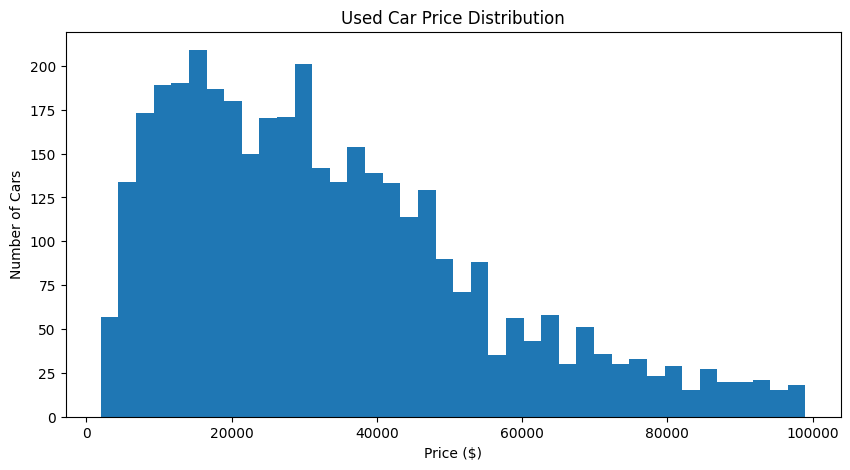

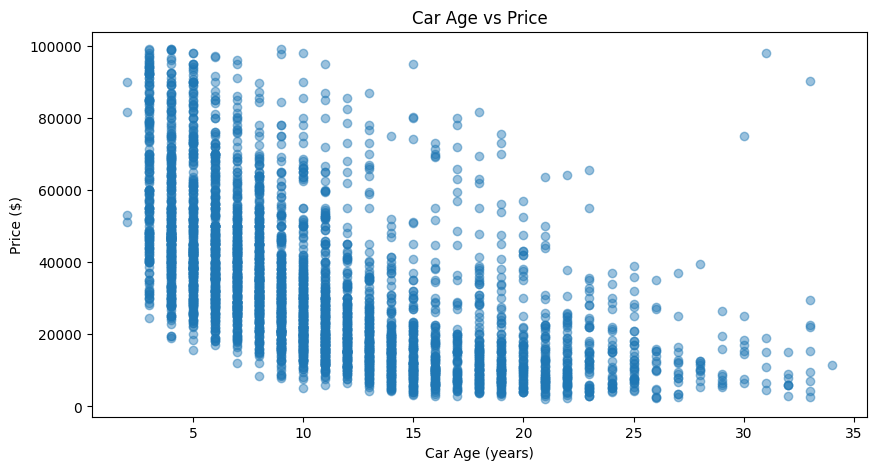

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(data["price"], bins=40)
plt.xlabel("Price ($)")
plt.ylabel("Number of Cars")
plt.title("Used Car Price Distribution")
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(data["car_age"], data["price"], alpha=0.45)
plt.xlabel("Car Age (years)")
plt.ylabel("Price ($)")
plt.title("Car Age vs Price")
plt.show()


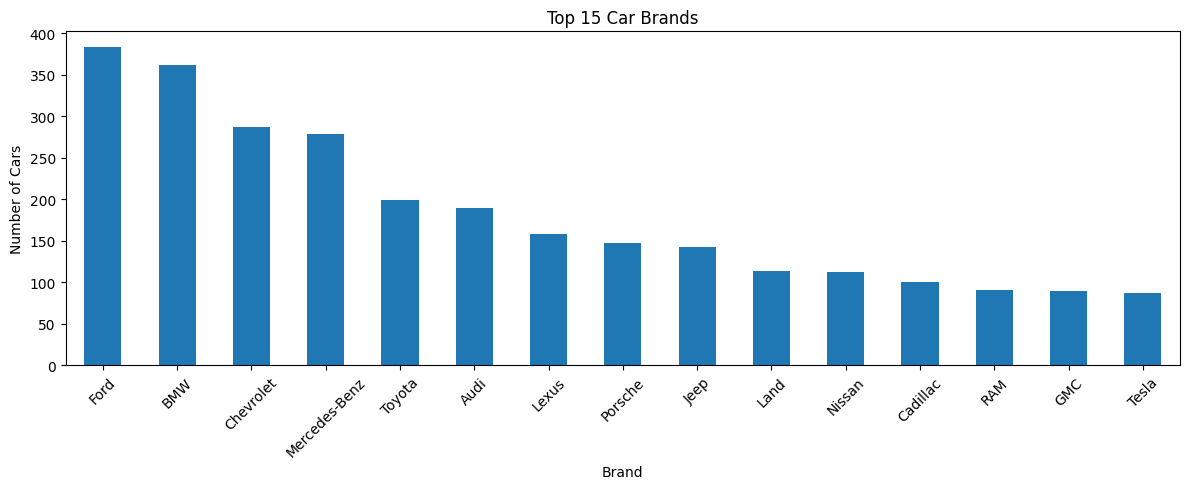

In [ ]:
plt.figure(figsize=(12, 5))
data["brand"].value_counts().head(15).plot(kind="bar")
plt.title("Top 15 Car Brands")
plt.xlabel("Brand")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 4. Prepare features

In [ ]:
target = "price"

features = [
    "brand", "model", "model_year", "milage",
    "fuel_type", "engine", "transmission",
    "ext_col", "int_col", "accident", "clean_title",
    "car_age", "horsepower", "engine_liters",
    "cylinders", "mileage_per_year"
]

X = data[features].copy()
y = data[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

categorical_features = X.select_dtypes(include="object").columns.tolist()
numeric_features = X.select_dtypes(exclude="object").columns.tolist()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)
print("Categorical:", categorical_features)
print("Numeric:", numeric_features)


Training: (3012, 16)
Testing : (753, 16)
Categorical: ['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']
Numeric: ['model_year', 'milage', 'car_age', 'horsepower', 'engine_liters', 'cylinders', 'mileage_per_year']


## 5. Baseline — Ridge Regression

This gives us a simple reference model. It uses one-hot encoding for categorical columns.

In [ ]:
ridge_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

ridge_model = Pipeline([
    ("preprocessor", ridge_preprocessor),
    ("model", Ridge(alpha=10.0))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

ridge_r2 = r2_score(y_test, ridge_pred)
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = mean_squared_error(y_test, ridge_pred) ** 0.5

print("Ridge Regression")
print(f"R²   : {ridge_r2:.4f}")
print(f"MAE  : ${ridge_mae:,.2f}")
print(f"RMSE : ${ridge_rmse:,.2f}")


Ridge Regression
R²   : 0.7910
MAE  : $6,656.13
RMSE : $9,571.09


## 6. Main model — CatBoost Regressor

CatBoost is useful here because the dataset contains many categorical fields (`brand`, `model`, `engine`, transmission, colors, etc.). It can learn from these categories directly instead of creating a huge one-hot matrix.

In [ ]:
catboost_model = CatBoostRegressor(
    iterations=1000,
    depth=8,
    learning_rate=0.04,
    loss_function="RMSE",
    l2_leaf_reg=6,
    random_seed=42,
    verbose=False
)

cat_indices = [X_train.columns.get_loc(col) for col in categorical_features]

catboost_model.fit(
    X_train,
    y_train,
    cat_features=cat_indices
)

cat_pred = catboost_model.predict(X_test)

cat_r2 = r2_score(y_test, cat_pred)
cat_mae = mean_absolute_error(y_test, cat_pred)
cat_rmse = mean_squared_error(y_test, cat_pred) ** 0.5

print("CatBoost Regressor")
print(f"R²   : {cat_r2:.4f}")
print(f"MAE  : ${cat_mae:,.2f}")
print(f"RMSE : ${cat_rmse:,.2f}")


CatBoost Regressor
R²   : 0.8409
MAE  : $5,554.41
RMSE : $8,351.37


## 7. Model comparison

In [ ]:
results = pd.DataFrame({
    "Model": ["Ridge Regression", "CatBoost Regressor"],
    "R2": [ridge_r2, cat_r2],
    "MAE": [ridge_mae, cat_mae],
    "RMSE": [ridge_rmse, cat_rmse]
})

display(results.style.format({
    "R2": "{:.4f}",
    "MAE": "${:,.0f}",
    "RMSE": "${:,.0f}"
}))


,Model,R2,MAE,RMSE
0,Ridge Regression,0.7910,"$6,656","$9,571"
1,CatBoost Regressor,0.8409,"$5,554","$8,351"


## 8. Actual vs Predicted

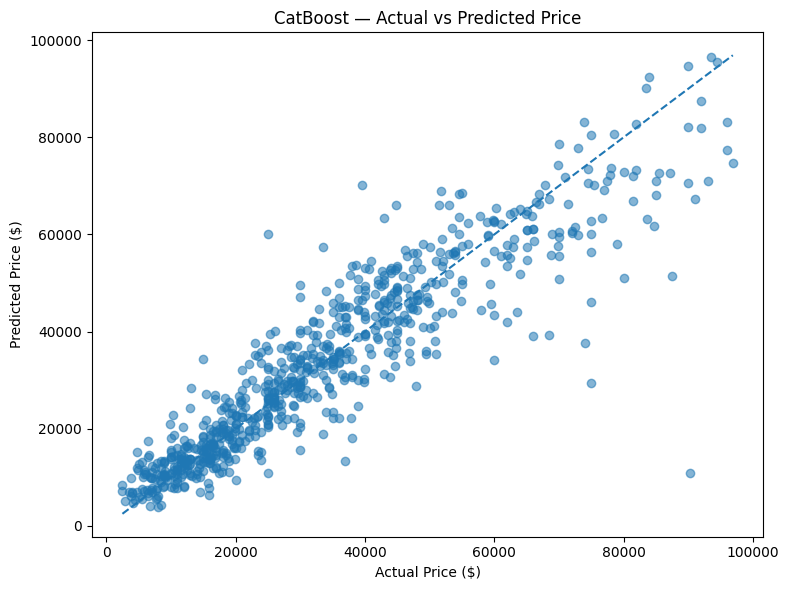

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, cat_pred, alpha=0.55)

line_min = min(y_test.min(), cat_pred.min())
line_max = max(y_test.max(), cat_pred.max())
plt.plot([line_min, line_max], [line_min, line_max], linestyle="--")

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("CatBoost — Actual vs Predicted Price")
plt.tight_layout()
plt.show()


## 9. Residual analysis

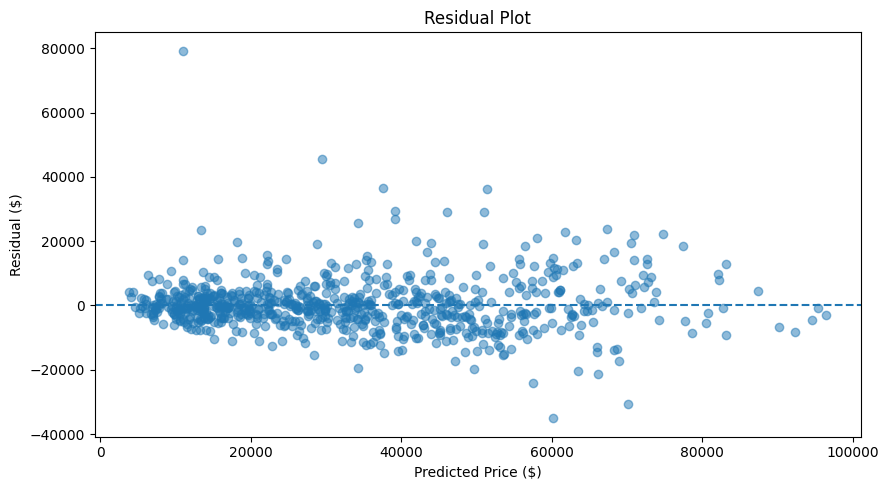

In [ ]:
residuals = y_test - cat_pred

plt.figure(figsize=(9, 5))
plt.scatter(cat_pred, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Price ($)")
plt.ylabel("Residual ($)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()


## 10. Feature importance

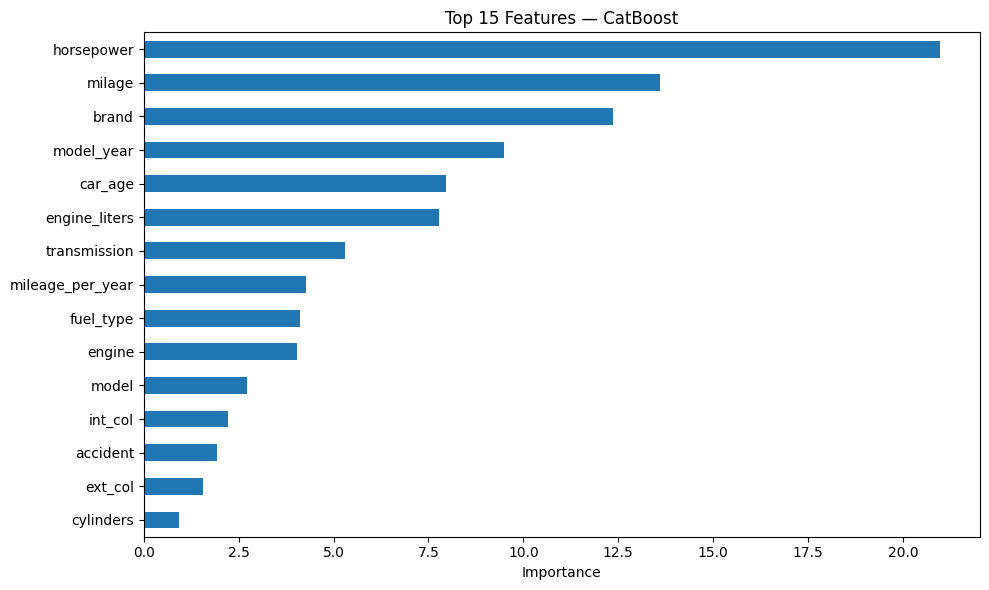

,Importance
horsepower,20.979140
milage,13.592552
brand,12.372940
model_year,9.493777
car_age,7.963112
engine_liters,7.784506
transmission,5.310002
mileage_per_year,4.267225
fuel_type,4.123141
engine,4.046745


In [ ]:
importance = pd.Series(
    catboost_model.get_feature_importance(),
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importance.head(15).sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 15 Features — CatBoost")
plt.tight_layout()
plt.show()

display(importance.head(15).to_frame("Importance"))


## 11. Test the model with one car

In [ ]:
def predict_car_price_model(
    brand, model, model_year, milage, fuel_type, engine,
    transmission, ext_col, int_col, accident, clean_title
):
    row = pd.DataFrame([{
        "brand": brand,
        "model": model,
        "model_year": model_year,
        "milage": milage,
        "fuel_type": fuel_type,
        "engine": engine,
        "transmission": transmission,
        "ext_col": ext_col,
        "int_col": int_col,
        "accident": accident,
        "clean_title": clean_title,
        "car_age": max(0, CURRENT_YEAR - model_year),
        "horsepower": pd.to_numeric(
            pd.Series([engine]).str.extract(r"(\d+(?:\.\d+)?)HP", expand=False),
            errors="coerce"
        ).fillna(data["horsepower"].median()).iloc[0],
        "engine_liters": pd.to_numeric(
            pd.Series([engine]).str.extract(r"(\d+(?:\.\d+)?)L", expand=False),
            errors="coerce"
        ).fillna(data["engine_liters"].median()).iloc[0],
        "cylinders": pd.to_numeric(
            pd.Series([engine]).str.extract(r"(\d+)\s*Cylinder", expand=False),
            errors="coerce"
        ).fillna(data["cylinders"].median()).iloc[0],
        "mileage_per_year": milage / max(1, CURRENT_YEAR - model_year)
    }])

    prediction = catboost_model.predict(row[features])[0]
    return max(0, prediction)

# Example
example_price = predict_car_price_model(
    brand="Ford",
    model="Utility Police Interceptor Base",
    model_year=2020,
    milage=50000,
    fuel_type="Gasoline",
    engine="2.0L I4 16V GDI DOHC Turbo",
    transmission="A/T",
    ext_col="Black",
    int_col="Black",
    accident="None reported",
    clean_title="Yes"
)

print(f"Estimated price: ${example_price:,.0f}")

Estimated price: $33,084


## 12. Save the model for the UI

The saved model is loaded by the Streamlit UI in `app.py` - run it with:```
streamlit run app.py
```

In [ ]:
MODEL_FILE = "used_car_price_catboost.cbm"
catboost_model.save_model(MODEL_FILE)

# Save the feature metadata needed by the UI
metadata = {
    "features": features,
    "current_year": CURRENT_YEAR,
    "price_lower_bound": float(data["price"].min()),
    "price_upper_bound": float(data["price"].max()),
    "medians": {
        "horsepower": float(data["horsepower"].median()),
        "engine_liters": float(data["engine_liters"].median()),
        "cylinders": float(data["cylinders"].median()),
    },
    "metrics": {
        "r2": float(cat_r2),
        "mae": float(cat_mae),
        "rmse": float(cat_rmse),
    },
    "rows_trained": int(len(data)),
    "price_stats": {
        "median": float(data["price"].median()),
        "mean": float(data["price"].mean()),
        "q25": float(data["price"].quantile(0.25)),
        "q75": float(data["price"].quantile(0.75)),
    },
    "price_sorted": np.sort(data["price"].to_numpy()).tolist(),
}

joblib.dump(metadata, "used_car_model_metadata.pkl")

print("Saved:")
print("-", MODEL_FILE)
print("- used_car_model_metadata.pkl")


Saved:
- used_car_price_catboost.cbm
- used_car_model_metadata.pkl


## 13. Final project notes

### What was improved
1. Removed duplicate rows.
2. Converted `milage` and `price` from text to numeric.
3. Handled missing categorical values as `Unknown`.
4. Added `car_age`.
5. Extracted horsepower, engine liters, and cylinders from `engine`.
6. Added `mileage_per_year`.
7. Removed extreme target outliers using the IQR rule instead of an arbitrary cutoff.
8. Added a Ridge baseline.
9. Added CatBoost for mixed categorical/numerical data.
10. Added R², MAE and RMSE.
11. Added actual-vs-predicted and residual plots.
12. Added feature importance.
13. Added a prediction function suitable for a UI.
14. Saved the trained model for Flask/Streamlit integration.

### Important interpretation
R² is not an "accuracy percentage" for regression. For this project, use **R², MAE and RMSE together**. The reported score depends on the train/test split and on the defined modeling population after outlier filtering.


In [ ]:
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output

# ------------------------------------------------------------
# 1. MAKE SURE YOUR DATASET IS LOADED
# ------------------------------------------------------------
# If your dataframe is already called df, this will use it.
# Otherwise uncomment the next line and change the path.

# df = pd.read_csv("your_dataset.csv")


# ------------------------------------------------------------
# 2. CLEAN DATA
# ------------------------------------------------------------

df_ui = df.copy()

df_ui["brand"] = df_ui["brand"].fillna("Unknown").astype(str).str.strip()
df_ui["model"] = df_ui["model"].fillna("Unknown").astype(str).str.strip()
df_ui["fuel_type"] = df_ui["fuel_type"].fillna("Unknown").astype(str).str.strip()
df_ui["engine"] = df_ui["engine"].fillna("Unknown").astype(str).str.strip()
df_ui["transmission"] = df_ui["transmission"].fillna("Unknown").astype(str).str.strip()
df_ui["ext_col"] = df_ui["ext_col"].fillna("Unknown").astype(str).str.strip()
df_ui["int_col"] = df_ui["int_col"].fillna("Unknown").astype(str).str.strip()
df_ui["accident"] = df_ui["accident"].fillna("Unknown").astype(str).str.strip()
df_ui["clean_title"] = df_ui["clean_title"].fillna("Unknown").astype(str).str.strip()

df_ui["model_year"] = pd.to_numeric(df_ui["model_year"], errors="coerce")

df_ui["milage"] = (
    df_ui["milage"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.extract(r"([0-9.]+)")[0]
)

df_ui["milage"] = pd.to_numeric(df_ui["milage"], errors="coerce")

df_ui = df.dropna(
    subset=[
        "brand",
        "model",
        "model_year",
        "milage",
        "price"
    ]
).reset_index(drop=True)

df_ui["model_year"] = df_ui["model_year"].astype(int)


# ------------------------------------------------------------
# 3. DROPDOWN CREATION
# ------------------------------------------------------------

brand_dropdown = widgets.Dropdown(
    options=sorted(df_ui["brand"].unique()),
    description="Brand:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="550px")
)

model_dropdown = widgets.Dropdown(
    options=[],
    description="Model:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="550px")
)

year_dropdown = widgets.Dropdown(
    options=[],
    description="Year:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="550px")
)

mileage_dropdown = widgets.Dropdown(
    options=[],
    description="Mileage:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="550px")
)

fuel_dropdown = widgets.Dropdown(
    options=[],
    description="Fuel:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="550px")
)

transmission_dropdown = widgets.Dropdown(
    options=[],
    description="Transmission:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="550px")
)

engine_dropdown = widgets.Dropdown(
    options=[],
    description="Engine:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="550px")
)

ext_color_dropdown = widgets.Dropdown(
    options=[],
    description="Ext. Color:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="550px")
)

int_color_dropdown = widgets.Dropdown(
    options=[],
    description="Int. Color:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="550px")
)

accident_dropdown = widgets.Dropdown(
    options=[],
    description="Accident:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="550px")
)

clean_title_dropdown = widgets.Dropdown(
    options=[],
    description="Clean Title:",
    style={"description_width": "120px"},
    layout=widgets.Layout(width="550px")
)


# ------------------------------------------------------------
# 4. PREDICT BUTTON
# ------------------------------------------------------------

predict_button = widgets.Button(
    description="🚗 Predict Car Price",
    button_style="success",
    layout=widgets.Layout(
        width="550px",
        height="45px"
    )
)

output = widgets.Output()


# ------------------------------------------------------------
# 5. FUNCTION TO UPDATE DROPDOWN OPTIONS
# ------------------------------------------------------------

def set_dropdown(dropdown, values):

    values = list(values)

    if len(values) == 0:
        dropdown.options = ["No option available"]
        dropdown.value = "No option available"

    else:
        dropdown.options = values
        dropdown.value = values[0]


# ------------------------------------------------------------
# 6. BRAND → UPDATE MODEL
# ------------------------------------------------------------

def update_models(change):

    brand = brand_dropdown.value

    filtered = df_ui[
        df_ui["brand"] == brand
    ]

    models = sorted(
        filtered["model"].unique()
    )

    set_dropdown(
        model_dropdown,
        models
    )

    update_other_options()


# ------------------------------------------------------------
# 7. MODEL → UPDATE OTHER OPTIONS
# ------------------------------------------------------------

def update_other_options(change=None):

    brand = brand_dropdown.value
    model = model_dropdown.value

    if model is None:
        return

    filtered = df_ui[
        (df_ui["brand"] == brand) &
        (df_ui["model"] == model)
    ]

    # YEAR
    set_dropdown(
        year_dropdown,
        sorted(filtered["model_year"].unique())
    )

    # MILEAGE
    set_dropdown(
        mileage_dropdown,
        sorted(filtered["milage"].unique()))

    # FUEL
    set_dropdown(
        fuel_dropdown,
        sorted(filtered["fuel_type"].unique())
    )

    # TRANSMISSION
    set_dropdown(
        transmission_dropdown,
        sorted(filtered["transmission"].unique())
    )

    # ENGINE
    set_dropdown(
        engine_dropdown,
        sorted(filtered["engine"].unique())
    )

    # EXTERIOR COLOR
    set_dropdown(
        ext_color_dropdown,
        sorted(filtered["ext_col"].unique())
    )

    # INTERIOR COLOR
    set_dropdown(
        int_color_dropdown,
        sorted(filtered["int_col"].unique())
    )

    # ACCIDENT
    set_dropdown(
        accident_dropdown,
        sorted(filtered["accident"].unique())
    )

    # CLEAN TITLE
    set_dropdown(
        clean_title_dropdown,
        sorted(filtered["clean_title"].unique())
    )


# ------------------------------------------------------------
# 8. PREDICTION
# ------------------------------------------------------------

def on_predict_button_click(button):

    with output:

        clear_output(wait=True)

        # Get selected values
        selected_data = {

            "brand":
                brand_dropdown.value,

            "model":
                model_dropdown.value,

            "model_year":
                year_dropdown.value,

            "milage":
                mileage_dropdown.value,

            "fuel_type":
                fuel_dropdown.value,

            "engine":
                engine_dropdown.value,

            "transmission":
                transmission_dropdown.value,

            "ext_col":
                ext_color_dropdown.value,

            "int_col":
                int_color_dropdown.value,

            "accident":
                accident_dropdown.value,

            "clean_title":
                clean_title_dropdown.value
        }

        try:

            # -----------------------------------------
            # USE YOUR TRAINED MODEL / PIPELINE
            # -----------------------------------------
            # Call the existing predict_car_price_model function from the global scope
            predicted_price = globals()['predict_car_price_model'](
                brand=selected_data['brand'],
                model=selected_data['model'],
                model_year=selected_data['model_year'],
                milage=selected_data['milage'],
                fuel_type=selected_data['fuel_type'],
                engine=selected_data['engine'],
                transmission=selected_data['transmission'],
                ext_col=selected_data['ext_col'],
                int_col=selected_data['int_col'],
                accident=selected_data['accident'],
                clean_title=selected_data['clean_title']
            )

            # -----------------------------------------
            # DISPLAY RESULT
            # -----------------------------------------

            print("\n")
            print("=" * 60)
            print("             🚗 USED CAR PRICE PREDICTION")
            print("=" * 60)

            print(
                f"Brand          : {selected_data['brand']}"
            )

            print(
                f"Model          : {selected_data['model']}"
            )

            print(
                f"Year           : {selected_data['model_year']}"
            )

            print(
                f"Mileage        : {selected_data['milage']}"
            )

            print(
                f"Fuel           : {selected_data['fuel_type']}"
            )

            print(
                f"Transmission   : {selected_data['transmission']}"
            )

            print(
                f"Engine         : {selected_data['engine']}"
            )

            print(
                f"Exterior Color : {selected_data['ext_col']}"
            )

            print(
                f"Interior Color : {selected_data['int_col']}"
            )

            print(
                f"Accident       : {selected_data['accident']}"
            )

            print(
                f"Clean Title    : {selected_data['clean_title']}"
            )

            print("-" * 60)

            print(
                f"💰 PREDICTED PRICE: ${predicted_price:,.2f}"
            )

            print("=" * 60)

        except Exception as e:

            print("Prediction Error:")
            print(e)


# ------------------------------------------------------------
# 9. CONNECT DROPDOWNS
# ------------------------------------------------------------

brand_dropdown.observe(
    update_models,
    names="value"
)

model_dropdown.observe(
    update_other_options,
    names="value"
)

predict_button.on_click(
    on_predict_button_click
)


# ------------------------------------------------------------
# 10. INITIALIZE
# ------------------------------------------------------------

update_models(
    {"new": brand_dropdown.value}
)


# ------------------------------------------------------------
# 11. DISPLAY UI
# ------------------------------------------------------------

title = widgets.HTML(
    """
    <h2 style="text-align:center;">
        🚗 Used Car Price Prediction
    </h2>

    <p style="text-align:center;">
        Select the car details from the options below
    </p>
    """
)

ui = widgets.VBox(
    [
        title,

        brand_dropdown,
        model_dropdown,
        year_dropdown,
        mileage_dropdown,
        fuel_dropdown,
        transmission_dropdown,
        engine_dropdown,
        ext_color_dropdown,
        int_color_dropdown,
        accident_dropdown,
        clean_title_dropdown,

        widgets.HTML("<br>"),

        predict_button,

        widgets.HTML("<br>"),

        output
    ],
    layout=widgets.Layout(
        width="600px",
        margin="auto"
    )
)

display(ui)